In [19]:
# Librerias base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Librerías de Scikit-Learn para Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report



In [2]:
# Cargare los datos de player y match
df_player_attr = pd.read_csv('../data/processed/clean/Player_Attributes_Clean.csv')
df_match = pd.read_csv('../data/processed/clean/Match_Clean.csv')

print(f"Forma de player atrributes: {df_player_attr.shape}")
print(f"Forma de match: {df_match.shape}")

Forma de player atrributes: (29739, 40)
Forma de match: (3040, 119)


In [ ]:
# Se decide aislar a cada jugador por su mejor version
# Esto para evitar un sobreentrenamiento donde aprenda de varias versiones del jugador


# Se ordena 'overall_rating' de forma descendente y se queda con cada fila del primer jugador
df_peak_players = df_player_attr.sort_values(by="overall_rating", ascending=False).drop_duplicates(subset=['player_api_id'], keep='first').copy()

print(f"Total de jugadores únicos listos para clasificar: {len(df_peak_players)}")
display(df_peak_players[["player_api_id", "overall_rating", "date"]].head())


Total de jugadores únicos listos para clasificar: 1500


,player_api_id,overall_rating,date
18050,30981,94.0,2015-09-21
5768,30893,93.0,2015-09-25
11183,39989,92.0,2007-02-22
29349,39854,92.0,2011-08-30
2242,30955,91.0,2011-08-30


Al no contar con en la tabla match con las posiciones, la desicion que tomamos es ajustar con las cordenadas

Y = 1: Portero (GK)

Y = 2 a 4: Defensa (DEF)

Y = 5 a 8: Mediocampista (MID)

Y = 9 a 11: Delantero (FWD)

Reconocemos que existe un problema con este ajuste, la posibilidad de que identifique a un defensa como mediocentro, o un delantero como medio, esto porque los equipos no juegan siempre con posiciones especificas, pueden jugar con 5 defensas, 3 medios, un delantero, etc.

In [ ]:
# Voy a crear una lista para extraer atodos los jugadores local y visitante
posiciones_lista = []

# Creo una iteracion del 1 al 11 para sacar las coordenadas de los 22 jugadores en cancha
for i in range(1, 12):
    # Jugadores locales
    df_home = df_match[[f"home_player_{i}", f"home_player_Y{i}"]].copy()
    df_home.columns = ["player_api_id", "y_coord"]
    posiciones_lista.append(df_home)
    
    # Jugadores visitantes
    df_away = df_match[[f"away_player_{i}", f"away_player_Y{i}"]].copy()
    df_away.columns = ["player_api_id", "y_coord"]
    posiciones_lista.append(df_away)

# Voy a unir todo en un DataFrame, aun y si tiene nulos
df_todas_posiciones = pd.concat(posiciones_lista, ignore_index=True)

# Aislo y cuento  los nulos antes de borrarlos
df_posiciones_nulas = df_todas_posiciones[df_todas_posiciones.isna().any(axis=1)]
print(f"Total de posiciones/jugadores nulos en el registro: {len(df_posiciones_nulas)}")

# Muestro cuales son los jugadores
if not df_posiciones_nulas.empty:
    print("Muestra de los registros nulos (jugadores o coordenadas sin identificar):")
    display(df_posiciones_nulas.head())

# Al ver que ningun jugador tiene el id se crea un DataFrame limpio eliminando los jugadores vacios
df_posiciones_limpias = df_todas_posiciones.dropna().copy()

Total de posiciones/jugadores nulos en el registro: 399
Muestra de los registros nulos (jugadores o coordenadas sin identificar):


,player_api_id,y_coord
134,NaN,1.0
152,NaN,1.0
172,NaN,1.0
176,NaN,1.0
190,NaN,1.0


In [5]:
# 3. Traducimos las posiciones a estimados de posicion
def clasificar_posicion(y):
    if y == 1.0: return 'GK'         # Portero
    elif y > 1.0 and y <= 4.0: return 'DEF'  # Defensa
    elif y > 4.0 and y <= 8.0: return 'MID'  # Mediocampista
    else: return 'FWD'               # Delantero

# Se aplica la definicion
df_todas_posiciones['position'] = df_todas_posiciones['y_coord'].apply(clasificar_posicion)

# 4. En caso de tener varios roles en los partidos, se queda con la moda de posicion de cada jugador
df_target = df_todas_posiciones.groupby('player_api_id')['position'].agg(lambda x: x.mode()[0]).reset_index()

print(f" Se etiquetaron las posiciones de {len(df_target)} jugadores únicos.")
print("\nDistribución de clases para el modelo KNN:")
display(df_target['position'].value_counts())

 Se etiquetaron las posiciones de 1500 jugadores únicos.

Distribución de clases para el modelo KNN:


position
MID    647
DEF    509
FWD    231
GK     113
Name: count, dtype: int64

In [6]:
df_peak_players.head(5)
# df_target.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,crossing,finishing,heading_accuracy,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
18050,102485,158023,30981,2015-09-21,94.0,95.0,left,80.0,93.0,71.0,...,90.0,74.0,13.0,23.0,21.0,6.0,11.0,15.0,14.0,8.0
5768,33332,20801,30893,2015-09-25,93.0,93.0,right,82.0,95.0,86.0,...,81.0,85.0,22.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0
11183,66758,1747,39989,2007-02-22,92.0,93.0,right,11.0,2.0,12.0,...,51.0,80.0,8.0,13.0,12.0,93.0,91.0,82.0,93.0,88.0
29349,180724,10535,39854,2011-08-30,92.0,92.0,right,85.0,70.0,51.0,...,97.0,75.0,55.0,62.0,61.0,5.0,15.0,12.0,5.0,9.0
2242,12790,41,30955,2011-08-30,91.0,93.0,right,85.0,74.0,54.0,...,93.0,65.0,57.0,57.0,56.0,6.0,13.0,6.0,13.0,7.0


Aunque posicion sea nuestro target, quiero hacer un eda bastante breve acorde al modelo de ML

In [10]:
# Se une la version con mas rating con la df target
df_knn = pd.merge(df_peak_players, df_target, on='player_api_id', how='inner')

# Voy a excluir las columnas que no me sean de utilidad y el target
columnas_excluir = [
    'id', 'player_fifa_api_id', 'player_api_id', 'date', 
    'preferred_foot', 'position'
]
target = 'position'


In [11]:
# Como todas las variables me son de utilidad, las separo, usare un for para no tener que escribir todas a mano

features = [col for col in df_knn.columns if col not in columnas_excluir]

X = df_knn[features]
y = df_knn[target]



In [12]:
X

,overall_rating,potential,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,94.0,95.0,80.0,93.0,71.0,88.0,85.0,96.0,89.0,90.0,...,90.0,74.0,13.0,23.0,21.0,6.0,11.0,15.0,14.0,8.0
1,93.0,93.0,82.0,95.0,86.0,81.0,87.0,93.0,88.0,77.0,...,81.0,85.0,22.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0
2,92.0,93.0,11.0,2.0,12.0,28.0,9.0,9.0,10.0,80.0,...,51.0,80.0,8.0,13.0,12.0,93.0,91.0,82.0,93.0,88.0
3,92.0,92.0,85.0,70.0,51.0,97.0,69.0,83.0,85.0,87.0,...,97.0,75.0,55.0,62.0,61.0,5.0,15.0,12.0,5.0,9.0
4,91.0,93.0,85.0,74.0,54.0,95.0,74.0,91.0,80.0,65.0,...,93.0,65.0,57.0,57.0,56.0,6.0,13.0,6.0,13.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,57.0,63.0,30.0,61.0,59.0,38.0,44.0,56.0,32.0,28.0,...,45.0,62.0,25.0,25.0,25.0,11.0,12.0,9.0,13.0,9.0
1496,57.0,62.0,8.0,13.0,13.0,12.0,13.0,13.0,19.0,15.0,...,27.0,14.0,12.0,11.0,14.0,65.0,54.0,50.0,46.0,63.0
1497,56.0,70.0,34.0,56.0,55.0,42.0,54.0,45.0,63.0,32.0,...,63.0,56.0,23.0,23.0,50.0,18.0,23.0,40.0,23.0,23.0
1498,56.0,68.0,50.0,25.0,53.0,50.0,22.0,48.0,32.0,34.0,...,39.0,42.0,55.0,60.0,57.0,7.0,7.0,8.0,8.0,12.0


In [15]:
# Me voy a asegurar que todo sea numero
print("\nTipos de datos en la matriz X:")
display(X.dtypes.value_counts())

# Minimos y maximos de cada stat
print("\nEstadísticas descriptivas:")
display(X.describe().T[['min', 'mean', 'max']])


Tipos de datos en la matriz X:


float64    35
Name: count, dtype: int64


Estadísticas descriptivas:


,min,mean,max
overall_rating,54.0,75.454667,94.0
potential,58.0,78.825333,95.0
crossing,8.0,59.965333,93.0
finishing,2.0,54.600667,95.0
heading_accuracy,1.0,60.482000,95.0
short_passing,8.0,67.908000,97.0
volleys,3.0,51.424667,93.0
dribbling,3.0,63.439333,96.0
curve,7.0,58.549333,91.0
free_kick_accuracy,5.0,55.306667,94.0


Histogramas de nuestros datos


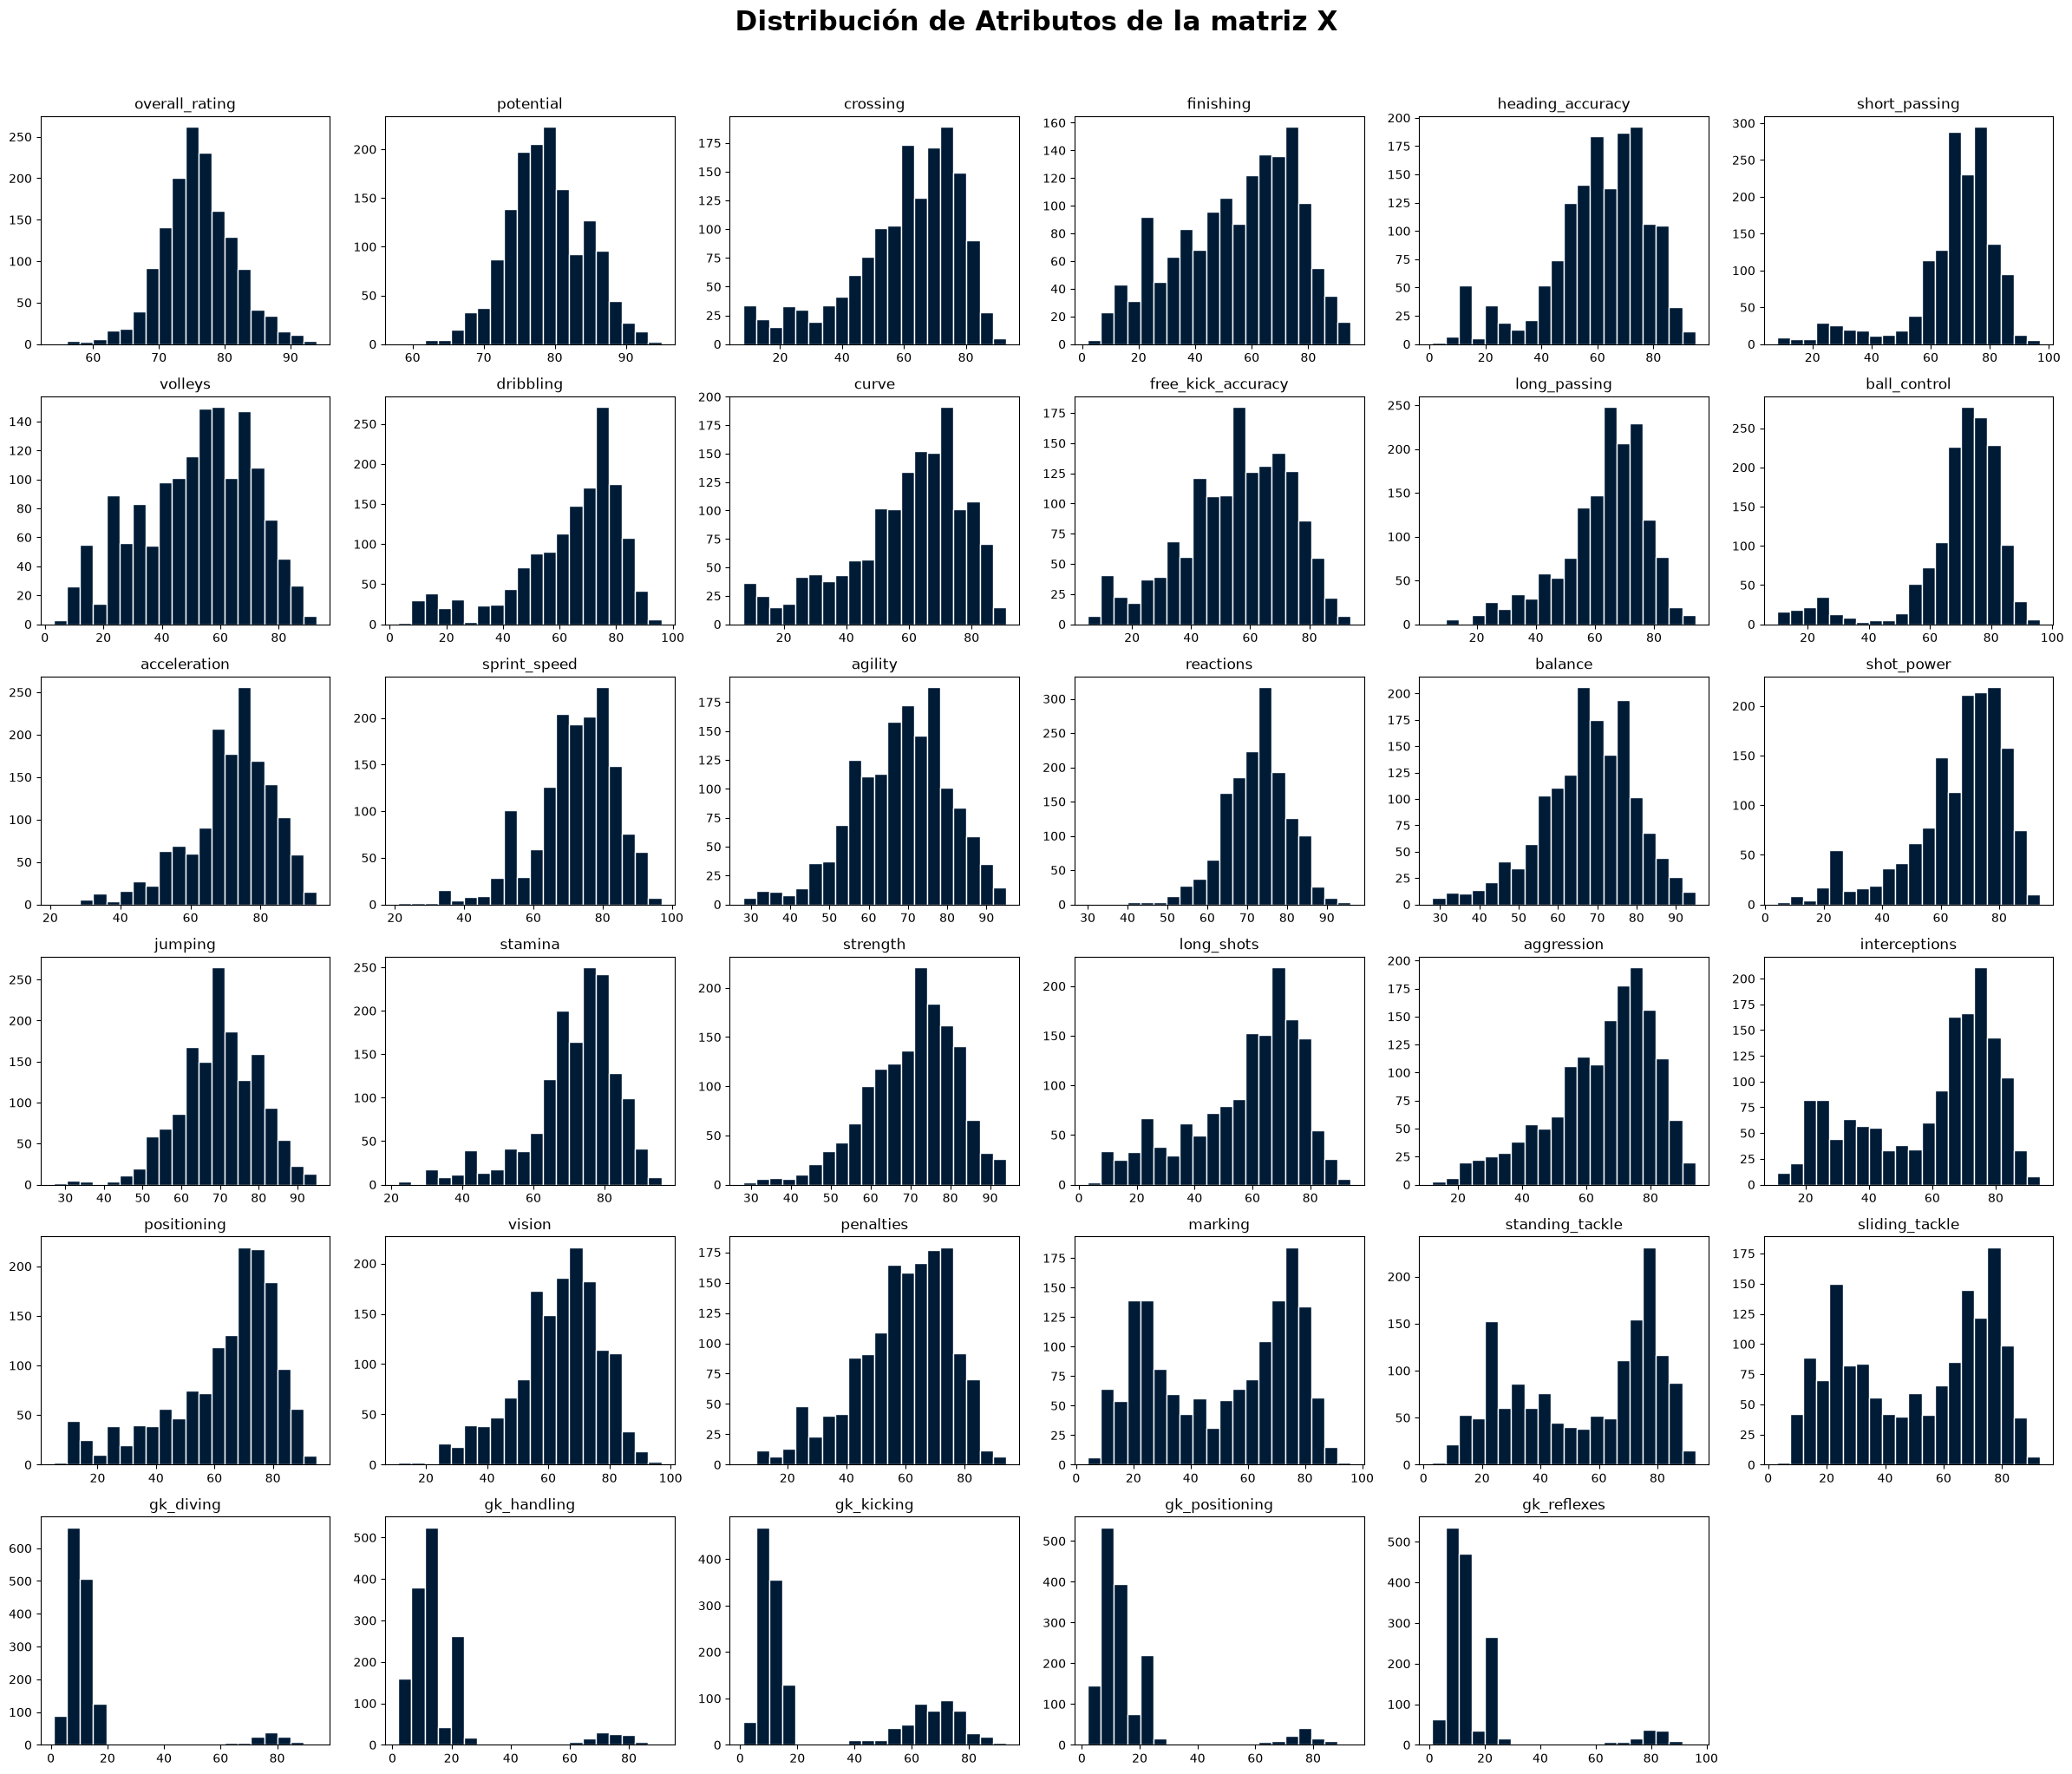

In [16]:
print("Histogramas de nuestros datos")

X.hist(bins=20, figsize=(24, 20), color='#001b36', edgecolor='white', grid=False)

plt.suptitle('Distribución de Atributos de la matriz X', fontsize=22, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Me sorprende que los datos estan bastante bien distribuidos, segurament se deba del 0 al 100, datos como portero son defnitivamente biniomales mientras que otros son mas uniformes, ante esto veo bien estandarizar todo con minmax scaler

In [17]:
# 1. Train-Test (80% Entrenamiento - 20% Prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # stratify=y me asegura que la distribucion sea la misma por las posiciones

In [20]:
# Escalado con MinMaxScaler 
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled

array([[0.425     , 0.48648649, 0.58823529, ..., 0.64130435, 0.23863636,
        0.22340426],
       [0.45      , 0.48648649, 0.68235294, ..., 0.10869565, 0.09090909,
        0.10638298],
       [0.6       , 0.64864865, 0.87058824, ..., 0.07608696, 0.125     ,
        0.06382979],
       ...,
       [0.45      , 0.37837838, 0.43529412, ..., 0.05434783, 0.07954545,
        0.09574468],
       [0.575     , 0.64864865, 0.78823529, ..., 0.15217391, 0.04545455,
        0.12765957],
       [0.55      , 0.54054054, 0.87058824, ..., 0.06521739, 0.13636364,
        0.11702128]], shape=(1200, 35))

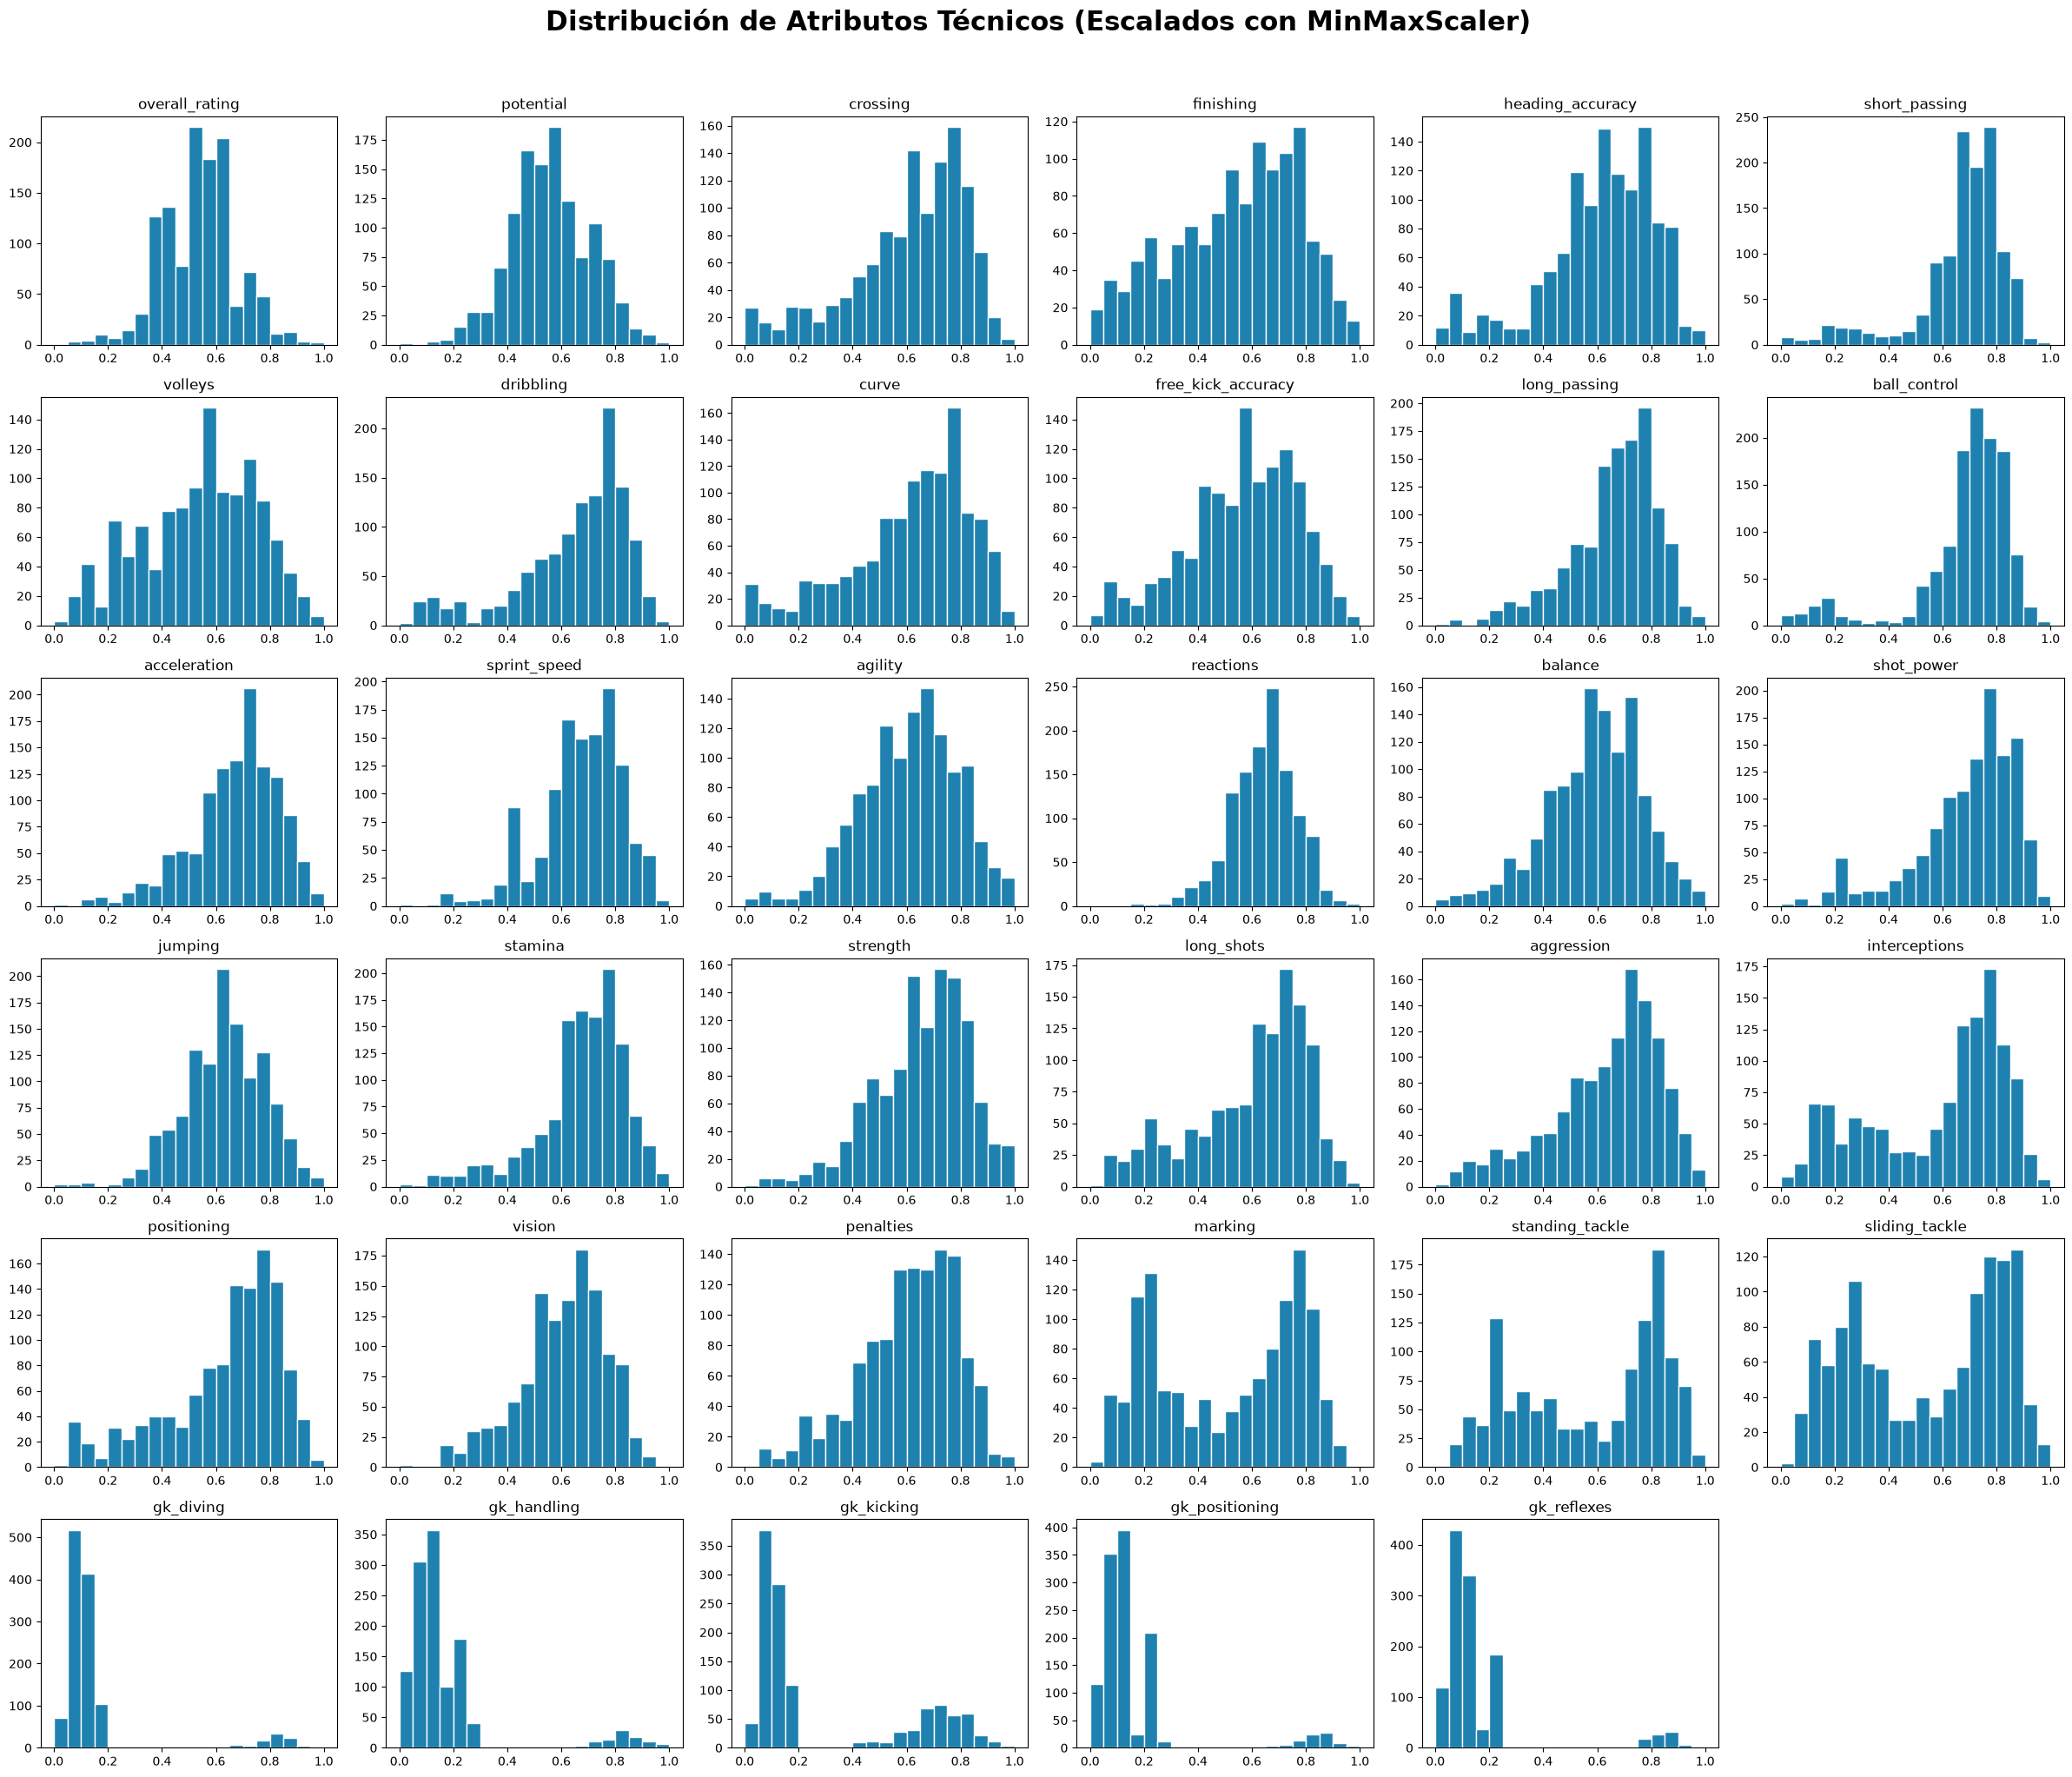


Comprobación de límites post-escalado:


,min,mean,max
overall_rating,0.0,0.534937,1.0
potential,0.0,0.560405,1.0
crossing,0.0,0.607902,1.0
finishing,0.0,0.540549,1.0
heading_accuracy,0.0,0.608456,1.0
short_passing,0.0,0.671498,1.0
volleys,0.0,0.538704,1.0
dribbling,0.0,0.650430,1.0
curve,0.0,0.614048,1.0
free_kick_accuracy,0.0,0.565712,1.0


In [33]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_train_scaled_df.hist(bins=20, figsize=(24, 20), color="#1e81b0", edgecolor="white", grid=False)

plt.suptitle("Distribución de Atributos Técnicos (Escalados con MinMaxScaler)", fontsize=22, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Comprobación matemática de los límites
print("\nComprobación de límites post-escalado:")
display(X_train_scaled_df.describe().T[["min", "mean", "max"]])

In [56]:
# en un rango de 1 a 30 hago la busqueda del k ideal
k_values = range(1, 30)
accuracies = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred_temp))

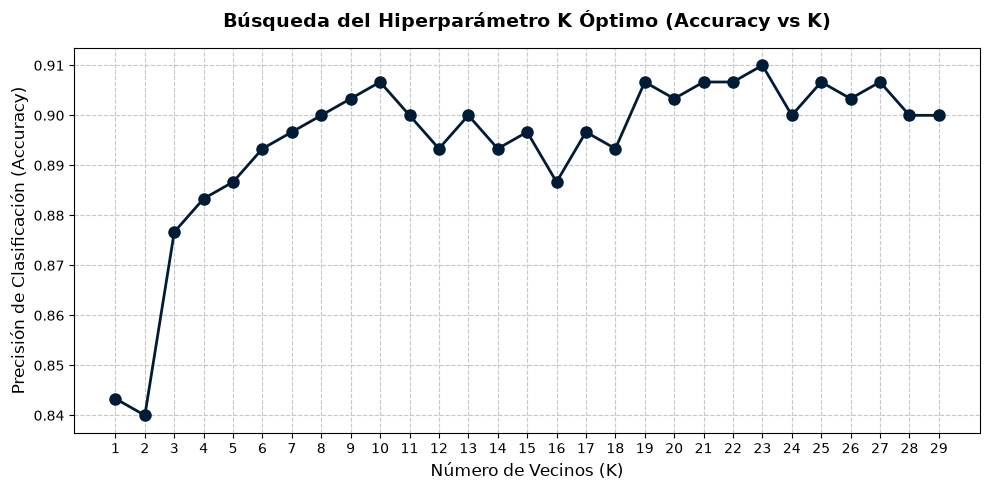

In [57]:
# Visualizo como se ve la curva ROC
plt.figure(figsize=(10, 5))
plt.plot(list(k_values), accuracies, marker='o', color='#001b36', linewidth=2, markersize=8)
plt.title('Búsqueda del Hiperparámetro K Óptimo (Accuracy vs K)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Vecinos (K)', fontsize=12)
plt.ylabel('Precisión de Clasificación (Accuracy)', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [58]:
# 5. Selección del mejor modelo
best_k = k_values[np.argmax(accuracies)]
max_acc = max(accuracies)

print(f"El mejor valor k optimo es {best_k}")

El mejor valor k optimo es 23



Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

         DEF       0.92      0.96      0.94       102
         FWD       0.86      0.80      0.83        46
          GK       1.00      1.00      1.00        23
         MID       0.90      0.89      0.89       129

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.92       300
weighted avg       0.91      0.91      0.91       300



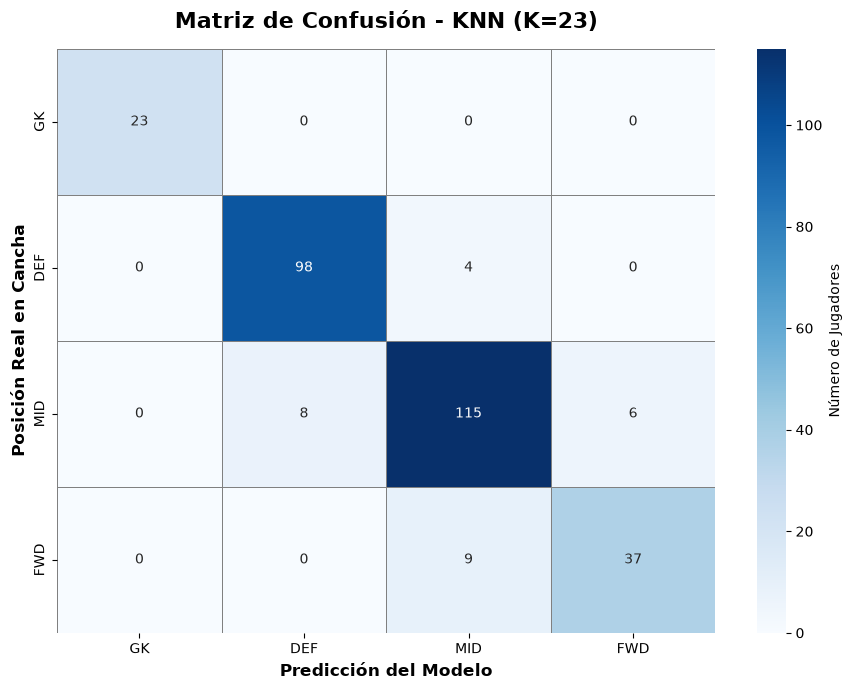

In [59]:
# Con el mejor K value entreno el modelo
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)

# Genero la prediccion con un set de test
y_pred_final = knn_final.predict(X_test_scaled)

# Precisión, Recall, F1-Score por posición
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred_final))

# Visualización de la Matriz de Confusión
plt.figure(figsize=(9, 7))

# Definimos el orden de las posciones
orden_cancha = ['GK', 'DEF', 'MID', 'FWD'] 

cm = confusion_matrix(y_test, y_pred_final, labels=orden_cancha)

# Mapa de calor
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=orden_cancha, yticklabels=orden_cancha,
            linewidths=0.5, linecolor='gray', cbar_kws={'label': 'Número de Jugadores'})

plt.title(f'Matriz de Confusión - KNN (K={best_k})', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12, fontweight='bold')
plt.ylabel('Posición Real en Cancha', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [60]:
# Llevare a cabo una validacion cruzada de 5 interaciones para comprobar que tan efectivo es el modelo
from sklearn.model_selection import cross_val_score
# cross_val_score divide internamente el set, entrena 5 veces y evalúa
puntuaciones_cv = cross_val_score(knn_final, X_train_scaled, y_train, cv=5, scoring='accuracy')

print(f"Accuracy de cada iteración: {np.round(puntuaciones_cv, 4)}")
print(f"Accuracy Promedio Real: {puntuaciones_cv.mean():.4f} ({(puntuaciones_cv.mean()*100):.2f}%)")
print(f"Desviación estándar (Margen de error): ±{puntuaciones_cv.std():.4f}")

Accuracy de cada iteración: [0.8833 0.9    0.8542 0.8625 0.8458]
Accuracy Promedio Real: 0.8692 (86.92%)
Desviación estándar (Margen de error): ±0.0198
